# 💳 Taller de Clustering — Parte 2: Tarjetas de crédito

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## ✅ Fase 07 · Comprensión del problema y de los datos — ya vista

> **Resumen fase 07:** **8.950 clientes × 18 columnas**, todas **numéricas** salvo `CUST_ID` (una **matrícula**: un valor distinto por cliente, no sirve para agrupar). **No hay etiqueta**. Escalas **muy distintas** (0–1 frente a miles) y **colas largas** (media ≫ mediana). Nulos: `CREDIT_LIMIT` (**1**) y `MINIMUM_PAYMENTS` (**313**). Búsqueda sistemática: 0 negativos y **8 frecuencias > 1** (imposibles).

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

df = pd.read_csv("docs/workshop/data/credit_card.csv")
df.head()

# ¿Cuántos clientes (filas) y cuántas variables (columnas)?
df.shape

# Tipos de datos: ¿hay texto o todo es número?
print(df.dtypes.value_counts())
df.dtypes

print("Valores distintos en CUST_ID:", df["CUST_ID"].nunique(), "de", len(df), "filas")
df["CUST_ID"].head()

# .T gira la tabla: una fila por variable, más fácil de leer
df.describe().T.round(2)

numericas = df.drop(columns="CUST_ID")
print("Valores negativos en todo el dataset:", (numericas < 0).sum().sum())

frecuencias = [c for c in df.columns if c.endswith("_FREQUENCY")]
print("\nFrecuencias mayores que 1:")
print((df[frecuencias] > 1).sum())

# ¿Quiénes son esos clientes con frecuencia > 1?
df.loc[df["CASH_ADVANCE_FREQUENCY"] > 1,
       ["CUST_ID", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX", "TENURE"]]

# Nulos por columna (solo las que tengan alguno)
nulos = df.isnull().sum()
nulos[nulos > 0]

float64    14
int64       3
str         1
Name: count, dtype: int64
Valores distintos en CUST_ID: 8950 de 8950 filas
Valores negativos en todo el dataset: 0

Frecuencias mayores que 1:
BALANCE_FREQUENCY                   0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              8
dtype: int64


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

## Fase 08 · Preparación de los datos

**Objetivo:** dejar los datos listos para medir distancias: **quitar** lo que no sirve, **corregir** lo imposible, **rellenar** nulos y **escalar**.

### 1. Quitar `CUST_ID`

Es una matrícula: no describe el comportamiento y, como número, metería ruido en las distancias (fase 07).

In [2]:
df = df.drop(columns="CUST_ID")
df.shape

(8950, 17)

### 2. Corregir las frecuencias imposibles

En la fase 07 encontramos **8 clientes** con `CASH_ADVANCE_FREQUENCY` > 1. Opciones:

| Opción | Ventaja | Inconveniente |
|---|---|---|
| Borrar esas filas | sencillo | perdemos 8 clientes reales |
| **Recortar a 1** | mantenemos a los clientes; 1 = «la máxima frecuencia» | cambiamos un poco el dato |

Son muy pocos y el resto de sus datos parece normal: **recortamos a 1** con `clip`.

In [3]:
df["CASH_ADVANCE_FREQUENCY"] = df["CASH_ADVANCE_FREQUENCY"].clip(upper=1)
print("Frecuencias > 1 tras corregir:", (df["CASH_ADVANCE_FREQUENCY"] > 1).sum())

Frecuencias > 1 tras corregir: 0


### 3. Rellenar los nulos: ¿media o mediana?

Antes de rellenar, miramos **cómo son** las columnas con nulos:

In [4]:
for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    print(f"{col:17}  media: {df[col].mean():8.1f}   mediana: {df[col].median():8.1f}   máximo: {df[col].max():9.1f}")

CREDIT_LIMIT       media:   4494.4   mediana:   3000.0   máximo:   30000.0
MINIMUM_PAYMENTS   media:    864.2   mediana:    312.3   máximo:   76406.2


En `MINIMUM_PAYMENTS` la **media (864)** es casi **el triple** que la **mediana (312)**: unos pocos clientes con pagos enormes (hasta 76.406) **tiran de la media hacia arriba**.

- *Analogía:* 9 personas cobran 1.500 € y entra un millonario que cobra 1.000.000 €. La **media** pasa a ~101.000 € (no describe a nadie); la **mediana** sigue en 1.500 €.
- La **mediana** (el valor del medio) **no se deja arrastrar** por los extremos → rellenamos con ella.

> 📖 **En los libros**
>
> - **Primer libro:** en las viviendas de California faltan **207** valores de `total_bedrooms`. Los rellena con `SimpleImputer(strategy="median")` (mediana = **434**) porque las columnas tienen **valores extremos**. Además, guarda esa mediana para rellenar **igual** los datos nuevos.
> - **Segundo libro:** en una red social, un usuario con **200 amigos** sube la **media** de 7,33 a 7,82, mientras la **mediana** se queda en **6**.

In [5]:
for col in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    df[col] = df[col].fillna(df[col].median())

print("Nulos que quedan:", df.isnull().sum().sum())

Nulos que quedan: 0


### 4. Colas largas: ver la forma de las variables

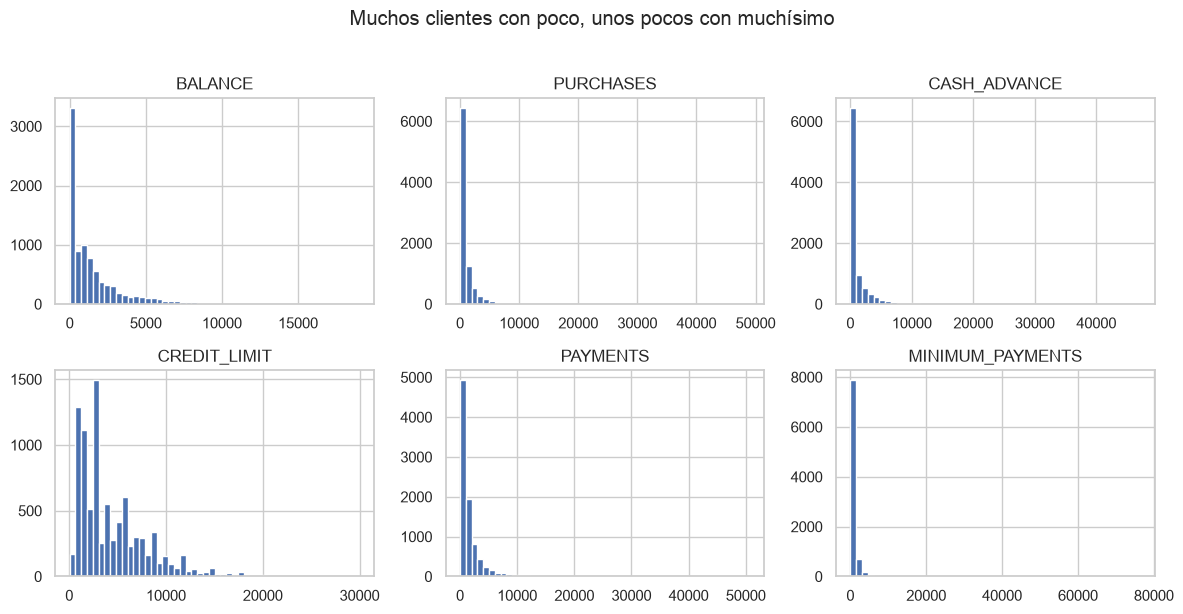

MINIMUM_PAYMENTS          13.9
ONEOFF_PURCHASES          10.0
PURCHASES                  8.1
INSTALLMENTS_PURCHASES     7.3
PAYMENTS                   5.9
CASH_ADVANCE_TRX           5.7
dtype: float64

In [6]:
cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
df[cols].hist(bins=50, figsize=(12, 6), layout=(2, 3))
plt.suptitle("Muchos clientes con poco, unos pocos con muchísimo", y=1.02)
plt.tight_layout(); plt.show()

# Asimetría (skew): 0 = simétrica; cuanto más alta, más larga la cola derecha
df.skew().sort_values(ascending=False).round(1).head(6)

Todas tienen una **cola larga a la derecha**: una barra altísima cerca de 0 y unos pocos clientes muy lejos. Es **típico en datos de dinero**. Para el clustering lo importante es saber que esos extremos existen (los veremos como **atípicos** en la fase 12).

> 📖 **En los libros**
>
> - **Primer libro:** los histogramas de California (población, habitaciones, ingresos) también tienen **cola larga**. Una solución es aplicar el **logaritmo** (`np.log`): la cola se encoge y la forma queda casi como una **campana**. *(Aquí no lo hacemos, para seguir el taller.)*
> - **Segundo libro:** dos conjuntos con la **misma media y desviación** pueden tener formas totalmente distintas: por eso hay que **mirar el histograma**, no solo `describe()`.

### 5. Escalar: que todas las variables pesen igual

**Por qué:** el clustering agrupa por **distancia**. Si una variable va de 0 a 30.000 (`CREDIT_LIMIT`) y otra de 0 a 1 (las frecuencias), **la grande decide sola**.

**`StandardScaler`** transforma cada columna para que tenga **media 0 y desviación 1**: cada valor pasa a decir *«cuántas desviaciones está por encima o por debajo de la media»*.

![Parecido significa cercanía](assets/taller/f08-distancia.png)

![Por qué se escala antes de PCA](assets/taller/f08-escalar-vinos.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

**Lo comprobamos:** escalamos y, con **2.000 parejas de clientes al azar**, medimos qué **% de la distancia** entre ellos aporta cada variable, **antes y después** de escalar.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df)                # array escalado: lo usaremos en todas las fases siguientes
X_df = pd.DataFrame(X, columns=df.columns)

# Comprobación: media 0 y desviación 1 en todas las columnas
X_df.agg(["mean", "std"]).T.round(2).head(6)

,mean,std
BALANCE,0.0,1.0
BALANCE_FREQUENCY,0.0,1.0
PURCHASES,0.0,1.0
ONEOFF_PURCHASES,0.0,1.0
INSTALLMENTS_PURCHASES,0.0,1.0
CASH_ADVANCE,0.0,1.0


In [8]:
rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(df), 2000), rng.integers(0, len(df), 2000)   # 2000 parejas al azar

def aporte_por_variable(datos):
    d2 = (datos[i] - datos[j]) ** 2                          # lo que suma cada variable a la distancia²
    return (d2 / d2.sum(axis=1, keepdims=True)).mean(axis=0) * 100

pd.DataFrame({"% sin escalar": aporte_por_variable(df.values),
              "% escalado": aporte_por_variable(X)},
             index=df.columns).round(1).sort_values("% sin escalar", ascending=False)

,% sin escalar,% escalado
CREDIT_LIMIT,39.8,8.3
BALANCE,15.4,6.8
PAYMENTS,13.3,3.4
CASH_ADVANCE,11.2,4.5
PURCHASES,7.7,2.5
MINIMUM_PAYMENTS,5.4,2.4
ONEOFF_PURCHASES,4.2,2.6
INSTALLMENTS_PURCHASES,3.0,3.5
PURCHASES_TRX,0.0,3.7
PRC_FULL_PAYMENT,0.0,8.3


**Lectura:** sin escalar, **`CREDIT_LIMIT` decide el 40 %** de la distancia y las **9 variables pequeñas** (frecuencias, nº de compras, `TENURE`…) aportan **0,0 %**: para K-Means **no existirían**. Tras escalar, **todas aportan** (entre ~2 % y ~9 %).

> 📖 **En los libros**
>
> - **Segundo libro:** 3 personas (A, B, C) con altura y peso. Midiendo la altura en **pulgadas**, el vecino más cercano de B es **A**; en **centímetros**, pasa a ser **C**. ¡**Cambiar la unidad cambia los vecinos**! Por eso estandariza (media 0, desviación 1).
> - **Primer libro:** sin escalar, `total_rooms` (6 a 39.320) **aplasta** a `median_income` (0 a 15). Y en K-Means, sin escalar, los grupos salen **estirados** y peor separados.

> **Resumen fase 08:** quitamos `CUST_ID`, **recortamos a 1** las 8 frecuencias imposibles y rellenamos los nulos con la **mediana** (no se deja arrastrar por los extremos: en `MINIMUM_PAYMENTS` media 864 vs mediana 312). Las variables de dinero tienen **colas largas**. Con **`StandardScaler`** todas quedan con **media 0 y desviación 1**: antes, unas pocas variables grandes decidían casi toda la distancia; después, todas pesan.